# Quickstart

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/quickstart.ipynb)

Run a first well: read a bundled well, plot it, interpret it and export the
result. Every output shown is computed from that well. Run it with Petrophys
installed ([Installation](https://petrophys.netlify.app/installation.html)), or open it in Google Colab with the button
above and run it in your browser, with nothing to install
([New to Python?](https://petrophys.netlify.app/new_to_python.html)).

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

In [2]:
import os, sys, tempfile, textwrap, warnings
import pandas as pd

# Display settings for this page: whole table cells, three decimals, wrapped warnings.
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:.3f}".format)
warnings.formatwarning = lambda message, category, *args, **kwargs: textwrap.fill(
    f"{category.__name__}: {message}", 88, subsequent_indent="    ") + "\n"
if "google.colab" not in sys.modules:
    os.chdir(tempfile.mkdtemp())  # the files this page writes go to a scratch folder

In [3]:
import pandas as pd
import petrophys as pp

well = pp.read(pp.sample("30_6-5"))   # or the path to your own LAS file
well

Well(30/6-5, curves=20, samples=22176)

The well has 20 curves, logged from 177 m to 3556 m.

## Plot the raw logs

`pp.plot` plots a well or an interpretation. Here it plots the logs as read,
before any interpretation, and `tracks=` picks four of the layout's tracks. The
window, 2800–3000 m, brackets the Brent Group (2841–2958 m).

    to v/v. Verify source units.
    to v/v. Verify source units.


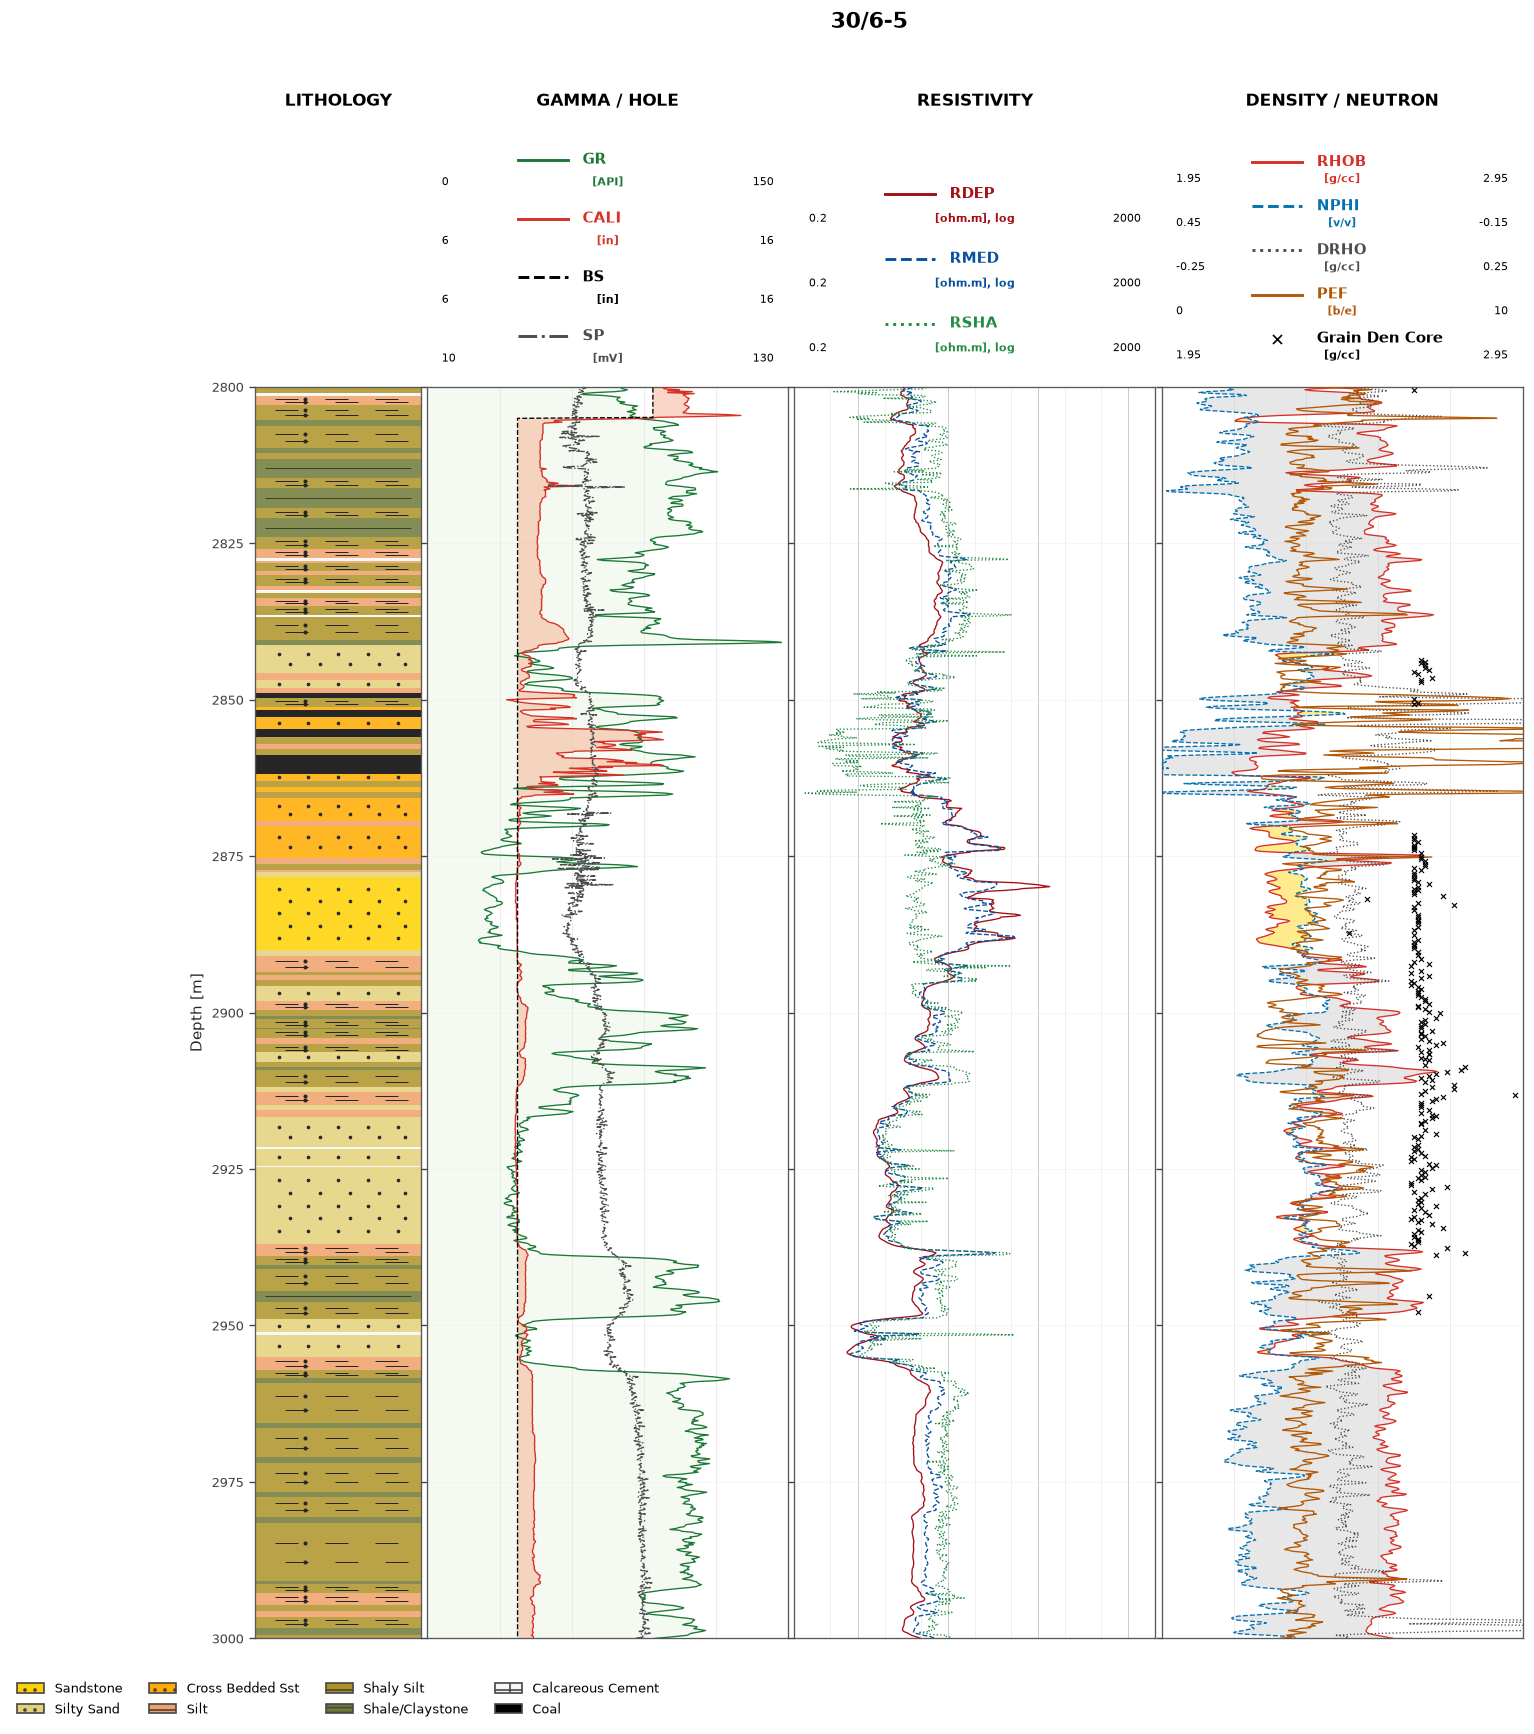

In [4]:
pp.plot(well, top=2800, bottom=3000,
        tracks=["LITHOLOGY", "GAMMA / HOLE", "RESISTIVITY", "DENSITY / NEUTRON"])

## Interpret

`pp.interpret` works on a copy of the well. Settings are keywords: here the
formation-water resistivity `rw` and the temperature it was measured at.
[Interpretation settings](https://petrophys.netlify.app/api/settings.html) lists them all.

In [5]:
result = pp.interpret(well, rw=0.07, rw_meas_temp_f=230)   # Rw 0.07 ohm.m at 230 degF
result.status

'interpreted'

`result.warnings` holds what the run wants you to check:

In [6]:
result.warnings

['lithology: PEF set aside: in 94% of 331 clean porous samples the apparent matrix density is quartz-like (< 2.67 g/cm3) but the apparent matrix U calcite-like (> 10 b/cm3), the signature of barite-weighted mud; minerals solved without PEF',
 "Bad hole removed 107.25 m of net pay (BAD_HOLE at 12631 of 22176 samples). Check the flag against the caliper and DRHO; bad_hole={'drho': ..., 'cali': ...} sets its thresholds and skip_steps=['bad_hole'] keeps the pay."]

The first says the photoelectric log (PEF) reads like barite-weighted mud, so
the minerals were solved without it. The second says how much net pay the
bad-hole flag removed over the whole well; [Implausible inputs and bad hole](https://petrophys.netlify.app/workflows.html#review-inputs) explains that
flag.

> **Note**
>
> The two `UserWarning` messages above the raw-log plot are real: this LAS labels
> its core saturations `SWC` and `SOC` as fractions, but they hold percentages.
> Petrophys divides them by 100 for plotting and core calibration and says so when
> it reads them (Python shows a warning once per place it is raised, so the
> interpretation does not repeat them here). They are Python warnings, not entries
> of `result.warnings`. The rest of this page hides only these warnings; see
> [Core saturation units](https://petrophys.netlify.app/input_templates.html#core-saturation-units).

In [7]:
# Hide only the SWC/SOC unit message explained above; other warnings stay visible.
warnings.filterwarnings("ignore", message=r"(SWC|SOC): inferred percent core saturation")

| `result.status` | Meaning |
| --- | --- |
| `"interpreted"` | Steps ran and produced interpretation curves. |
| `"no_interpretation"` | Nothing failed, but the inputs supported no interpretation step. |
| `"failed"` | A step failed; `result.errors` says why and `result.raise_for_errors()` raises. |

To see the original exception while debugging, pass `raise_on_error=True`.

A step that cannot run is skipped with a reason, never filled with invented
defaults:

In [8]:
result.specific_steps_skipped

{'spectral_gamma': 'Not run by the interpretation workflow; use petrophys.interpretation.geochemistry.interpret_spectral_gamma directly',
 'elemental_spectroscopy': 'Not run by the interpretation workflow; use petrophys.interpretation.geochemistry.interpret_elemental_spectroscopy directly',
 'hc_correction': 'apply_hc_correction=False (hydrocarbon correction is opt-in)',
 'porosity_refinement': 'Not run by the interpretation workflow; porosity is computed once in the porosity step'}

> **Where Rw comes from**
>
>
> Without `rw`, the workflow uses the first source it finds:
>
> 1. a formation-water salinity you set, `salinity_ppm`;
> 2. an `RW` value in the LAS header (at its `RWT`, or at `rw_meas_temp_f` when
>    you set one, else at the header formation temperature `FMT`);
> 3. the SP or Rxo/Rt response, given a mud-filtrate resistivity (water-based mud
>    only);
> 4. the apparent Rw of clean rock, with a warning: each sample's apparent Rw
>    is corrected from its own temperature to 75 degF, and the P5 of those
>    values is taken as one water for the whole well (values saltier than
>    saturated brine are left out). Use `zones=` where the water changes, for
>    example fresher shallow sands;
> 5. a default of 0.05 ohm.m, with a warning (`allow_default_rw=False` turns it
>    off).
>
> Always give the temperature Rw was measured at (`rw_meas_temp_f`); otherwise Rw
> is taken at the well's median formation temperature, with a warning.
> The 30/6-5 header gives `RW = 0.07` ohm.m at `RWT = 230` degF; this page
> passes the same values as settings, to show how you give your own.

## Read the trace

Every executed step records its method, inputs, outputs, parameters and
decisions. `result.to_dataframe()` gives one row per step, and
`result.print_trace()` prints every record in full.

In [9]:
result.to_dataframe()[["Step", "Status", "Method", "Output Curves"]]

,Step,Status,Method,Output Curves
0,normalization,OK,curve_alias_and_unit_standardization,"DRHO, PEF, GR, DTC, SWC, SOC"
1,input_context,OK,validated_geology_selection,
2,temperature,OK,linear_gradient_from_BHT,TEMP
3,bad_hole,OK,caliper_drho_flags,BAD_HOLE
4,vclay,OK,linear,"VCL, VCLAY, VCL_GR, VCLGR, VCL_SP, VCLSP, VCL_ND, VCLND"
5,rcl,OK,lithology_shale_median_rt,
6,rmf,OK,las_metadata_assumed_reference_temperature,RMF
7,porosity,OK,component_based,"PHIN, PHID, PHIS, PHIT, PHIE, PHI_SEC"
8,lithology,OK,canonical_multi_mineral_solver,"VQUAR, VCALC, VDOLO, VANHY"
9,core_correction,OK,same_well_core_correction,"PHIE_CC, PERM_CC"


The `rw` row shows which Rw source was used:
`user_provided_temperature_profile_corrected`, the Rw you gave, corrected from
230 degF to the temperature of each depth.

## Summarize the Brent Group

The log starts in shallow, poorly consolidated rock that can pass the pay
cutoffs (the clay, porosity and saturation limits). One Rw also serves the whole
well, while shallow formation waters are usually fresher than the reservoir's,
so shallow sections that no lithology code covers can be flagged as marginal
pay; [Where the pay sits](https://petrophys.netlify.app/workflows.html#review-pay) explains this limitation. Summarize the interval you
are evaluating, not the whole well.

In [10]:
result.summary()["net_thickness"]

{'depth_unit': 'm', 'net_rock': 1902.87, 'net_res': 786.69, 'net_pay': 50.9}

In [11]:
brent = result.summary(top=2841, bottom=2958)
brent["net_thickness"]

{'depth_unit': 'm', 'net_rock': 76.5, 'net_res': 65.99, 'net_pay': 25.3}

Of the 51 m of net pay in the whole well, 25 m lies in the Brent Group. The
statistics of the interpreted curves over the same window:

In [12]:
result.statistics(top=2841, bottom=2958)

,unit,samples,mean,p10,median,p90
VCL,v/v,768,0.356,0.011,0.233,0.835
PHIT,v/v,768,0.200,0.130,0.204,0.263
PHIE,v/v,768,0.128,0.000,0.148,0.232
SW,v/v,768,0.718,0.243,0.755,1.000
PERM,mD,636,60.451,0.000,17.136,212.236


## Plot the interpretation

Passing the result plots the interpreted well. The `petrophysics` template adds
porosity, saturation, permeability and pay-flag tracks.

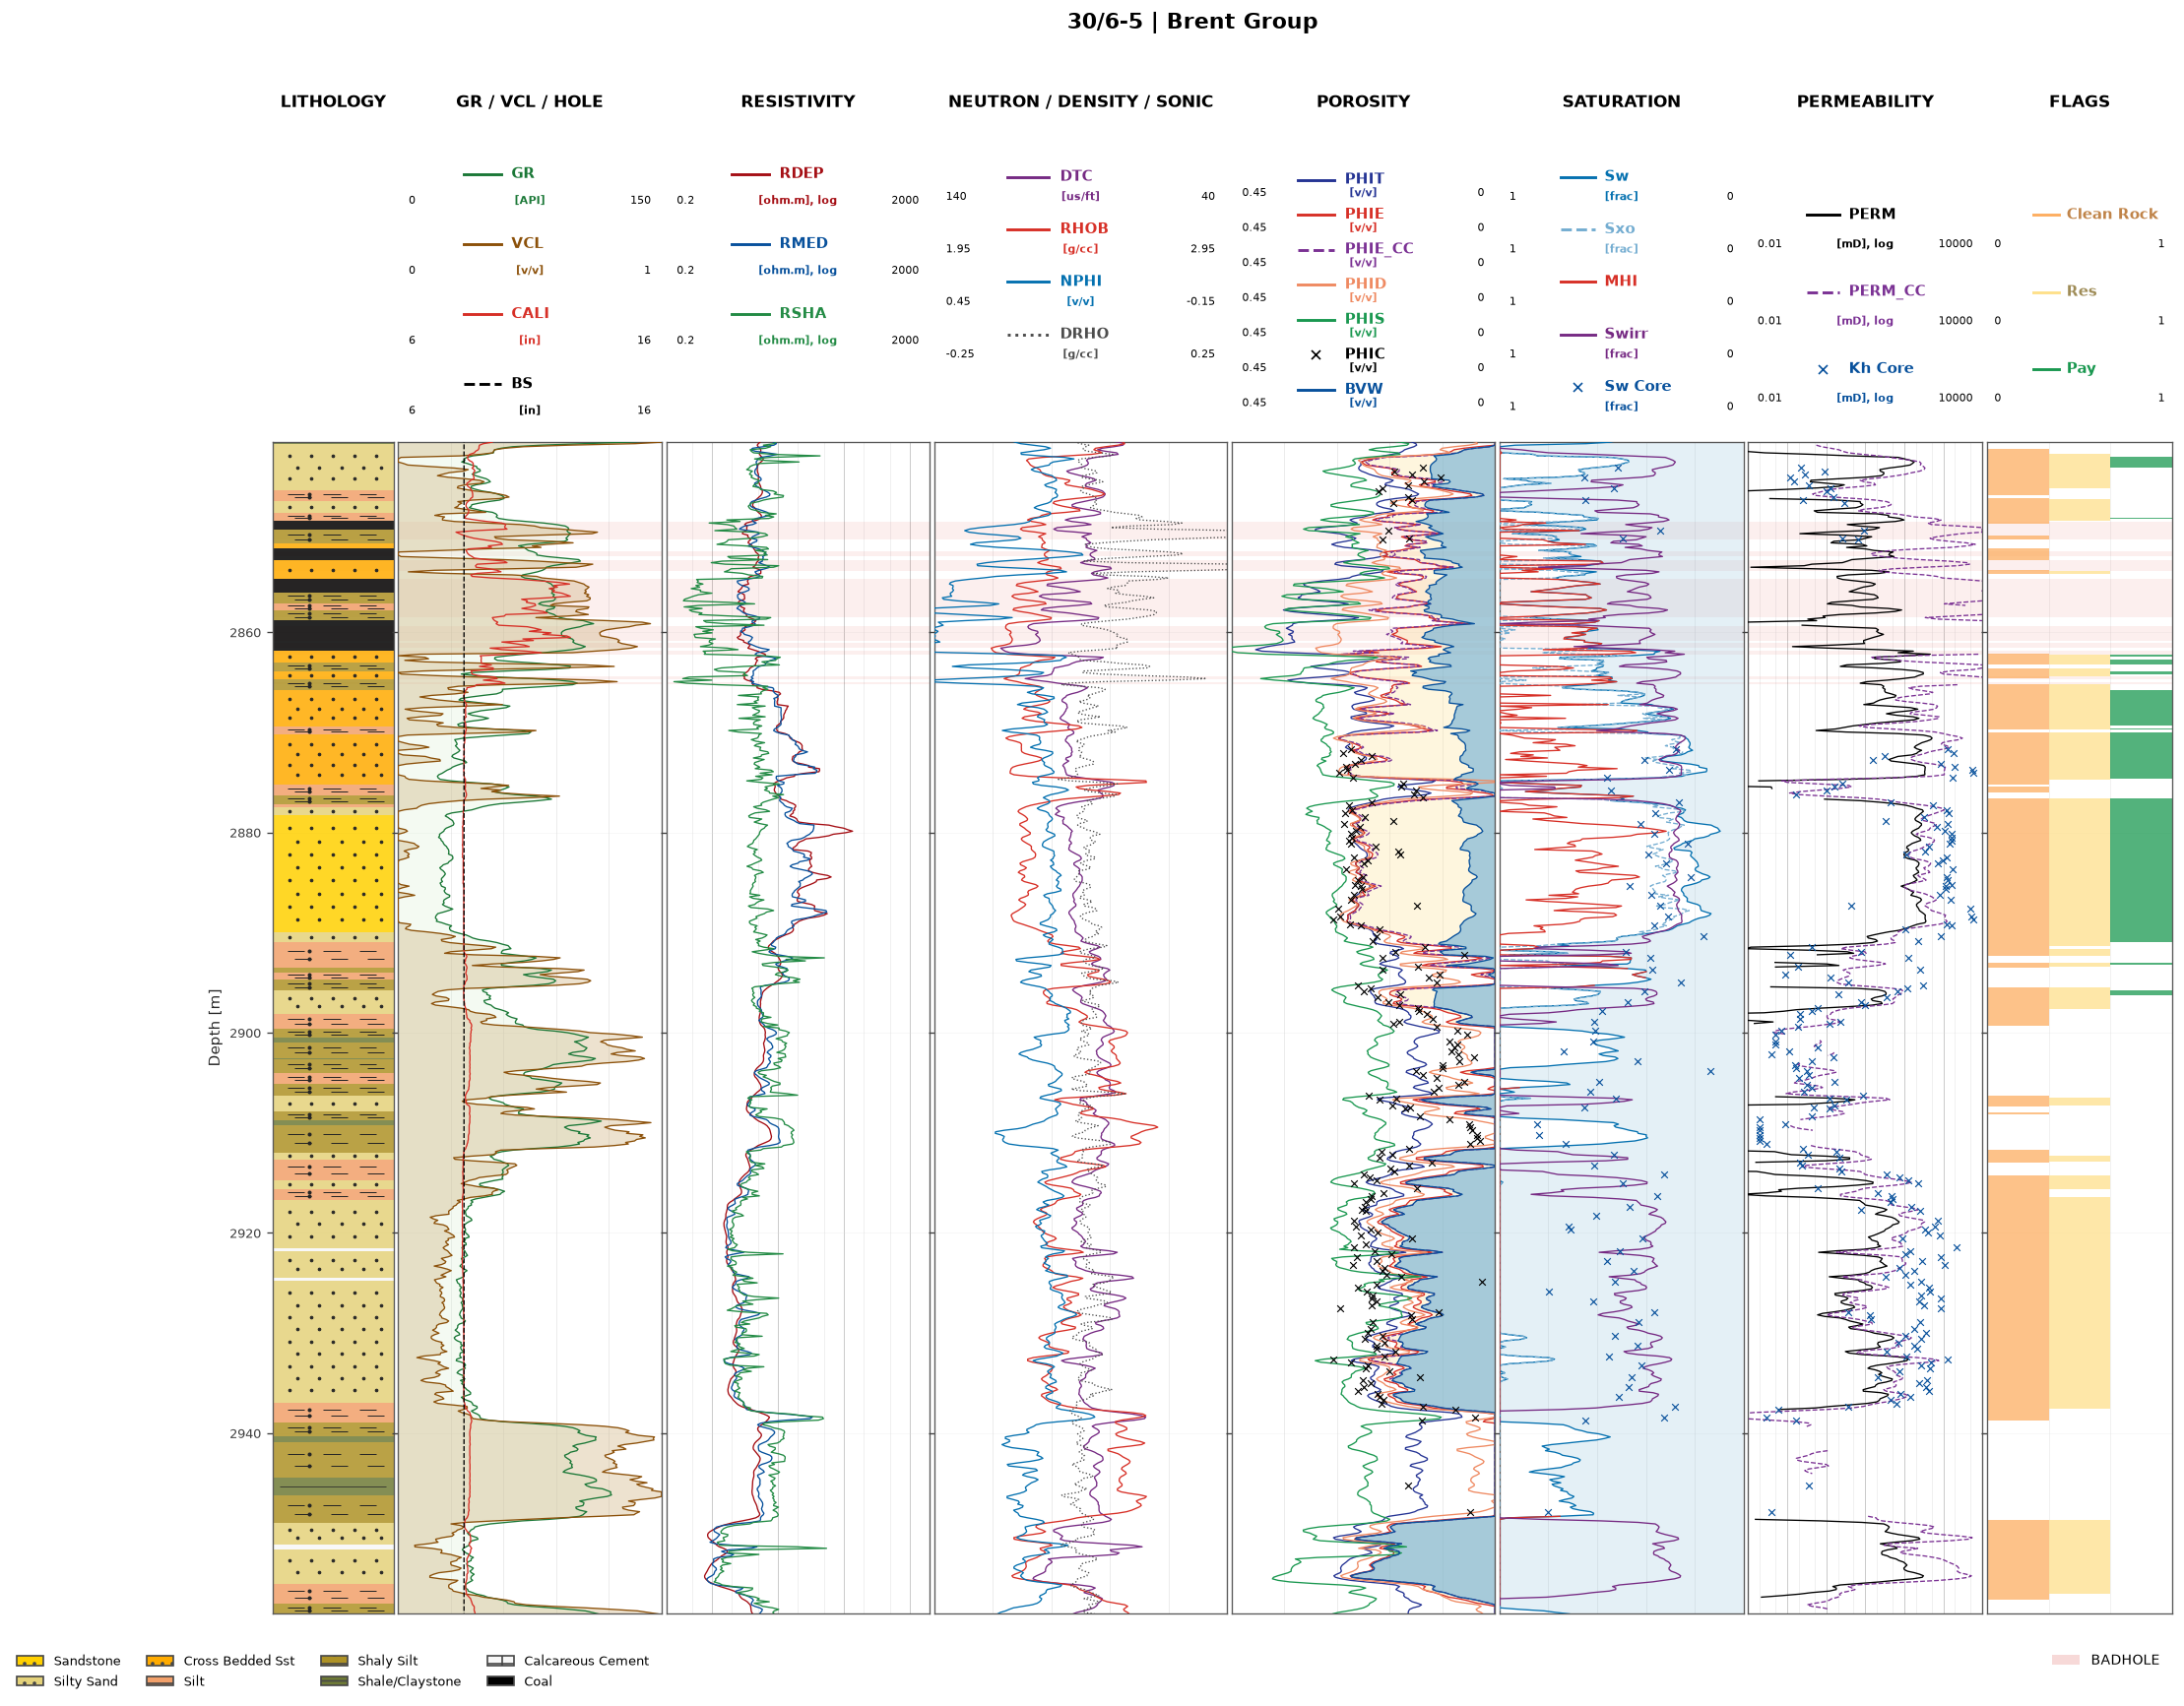

In [13]:
pp.plot(result, top=2841, bottom=2958, template="petrophysics",
        formation_name="Brent Group")

## Export

`to_las` writes every curve plus the settings used, as `PP_*` parameters in the
LAS header. `to_json` writes the complete trace.

In [14]:
result.to_las("30_6-5_interpreted.las")
result.to_json("30_6-5_trace.json");

The `PP_*` parameters written to the LAS:

In [15]:
pd.DataFrame(result.provenance_parameters())

,mnemonic,value,descr,unit
0,PP_VERSION,3.0.0,petrophys version,NaN
1,PP_STATUS,interpreted,Interpretation status,NaN
2,PP_DOMAIN,clastic,Lithology interpretation domain,NaN
3,PP_MATRIX,sandstone,Matrix used,NaN
4,PP_LITH,clastic,Lithology family used,NaN
5,PP_RW,0.070,Rw input at 230 degF (user_provided_temperature_profile_corrected),ohm.m
6,PP_RWTMIN,0.062,Minimum Rw at formation temperature,ohm.m
7,PP_RWTMAX,0.197,Maximum Rw at formation temperature,ohm.m
8,PP_SWMODEL,archie+simandoux,Water saturation model(s),NaN
9,PP_A,per lithology,Archie a from the lithology table,NaN


## Several wells

`pp.read` and `pp.interpret` take a folder, a file pattern (`"logs/*.las"`) or a list of files as well as one file.
A multi-well tops table is read once and each well keeps its own picks; every well is interpreted with the same settings, its own header values filling the rest.
One table covers all the wells, and `to_las(folder)` and `save_plots(folder)` write a file per well.
A well that fails is named in `results.failed`; the others are interpreted.

In [16]:
wells = pp.read([pp.sample(name) for name in ["HW-3", "HW-4", "HW-5"]],
                formations=pp.sample("formations_costa"))
results = pp.interpret(wells, lithology_domain="carbonate")
results.summary()

,Well,Status,Depth unit,Net rock,Net reservoir,Net pay,Median VCL,Median PHIE,Median SW,Median PERM,Warnings
0,HW-3,interpreted,ft,215.500,195.000,194.000,0.000,0.290,0.102,7.300,2
1,HW-4,interpreted,ft,180.500,142.500,4.000,0.000,0.180,1.000,2.550,3
2,HW-5,interpreted,ft,168.500,112.000,0.000,0.000,0.080,1.000,0.180,3


In [17]:
results.formation_summary()

    average covers the other pay samples.
    average covers the other pay samples.


,Well,Formation,Top,Bottom,Gross (ft),Net Rock (ft),Net Reservoir (ft),Net Pay (ft),N/G (reservoir),Pay/Gross,...,Avg GR,Avg RHOB,Avg NPHI,Avg RDEP,Avg PHIT,HCPV,BVW,Samples,Pay Samples,Data Coverage %
0,HW-3,KHARAIB-2,7805.000,8020.000,215.500,215.500,195.000,194.000,0.905,0.900,...,12.322,2.377,0.099,37.938,0.198,37.974,0.028,431,388,100.000
1,HW-4,KHARAIB-2,8150.000,8330.000,180.500,180.500,142.500,4.000,0.789,0.022,...,15.429,2.435,0.131,1.297,0.153,0.236,0.108,361,8,100.000
2,HW-5,KHARAIB-2,8182.000,8350.000,168.500,168.500,112.000,0.000,0.665,0.000,...,20.743,2.595,0.071,15.237,0.069,NaN,NaN,337,0,100.000


`pp.plot` on several wells draws each well's own log plot, one after another; `.save(folder)` writes a file per well.
With `curves=`, it draws one figure instead: a track per curve, with every well's curve in it.

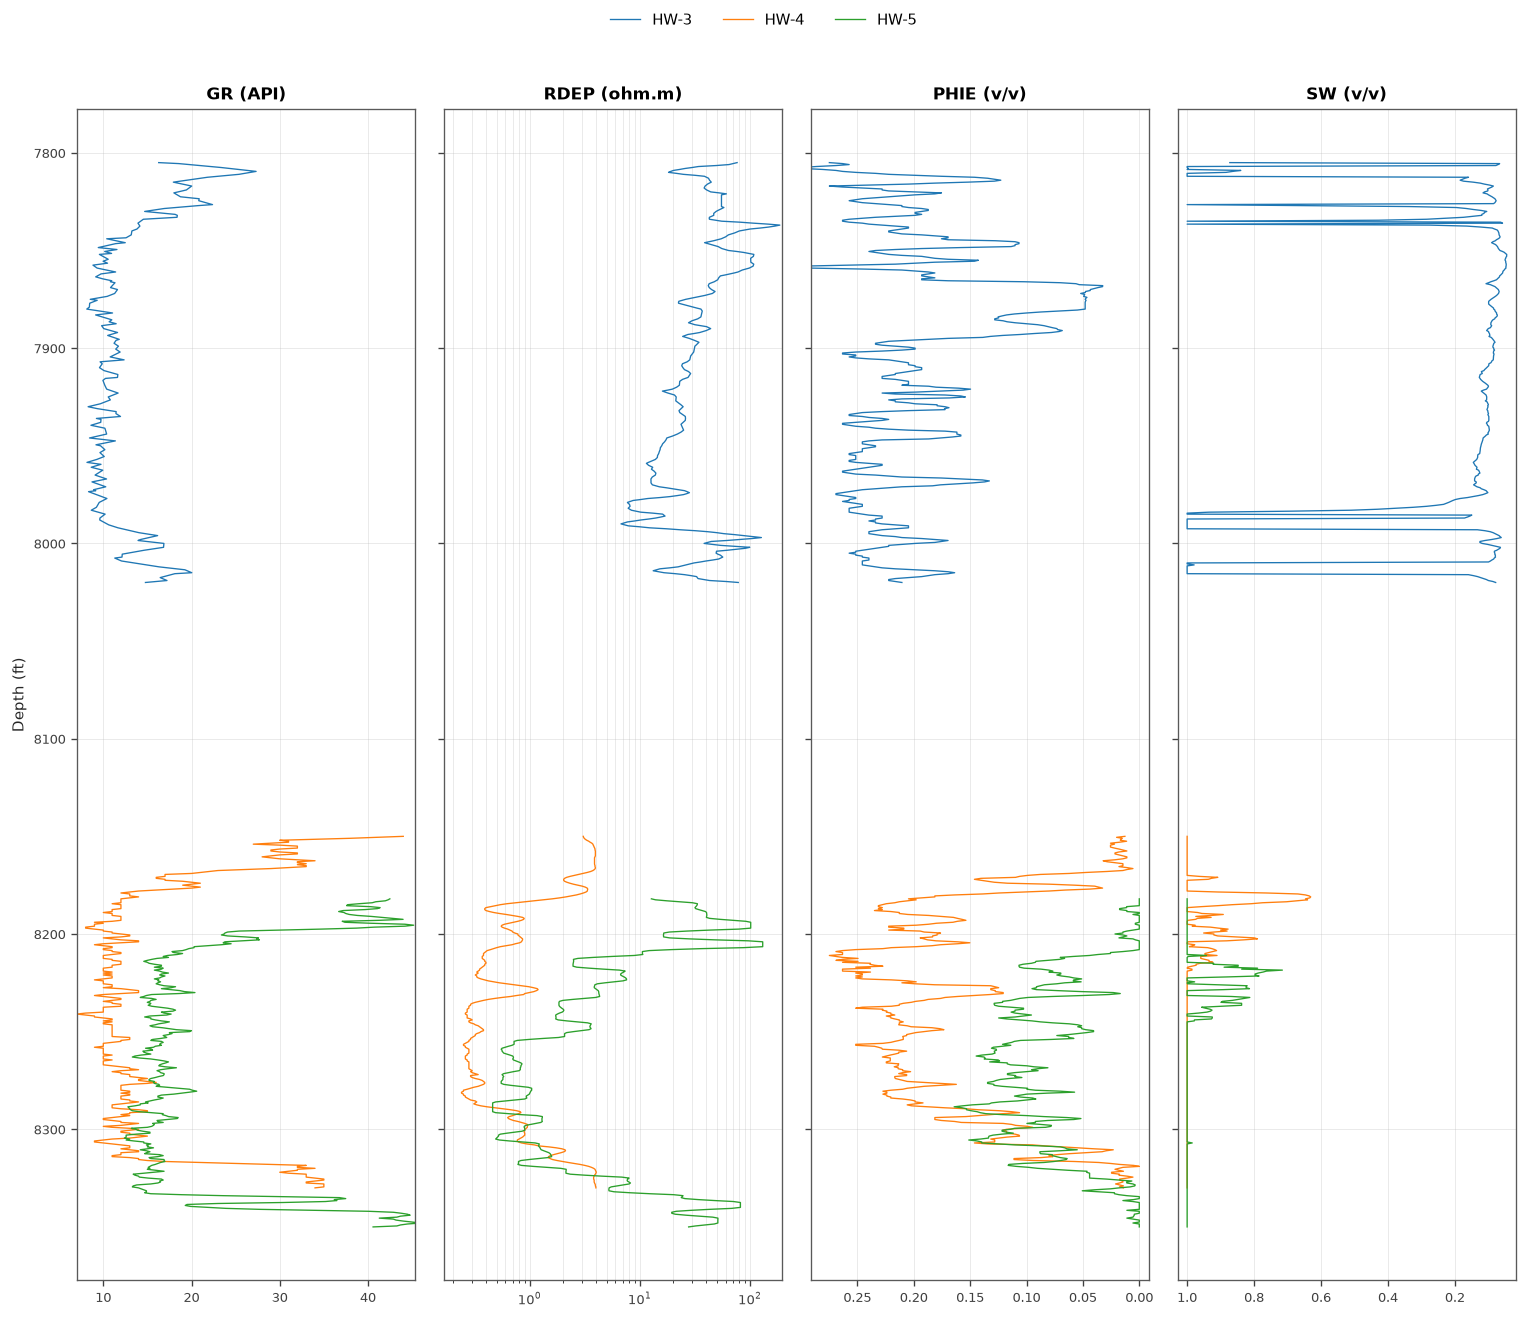

In [18]:
pp.plot(results, curves=["GR", "RDEP", "PHIE", "SW"])

## Next

[Your own data](https://petrophys.netlify.app/own_data.html): read your own CSV logs, attach formation and lithology tables, and check that their depths agree.

The [complete tour](https://petrophys.netlify.app/tutorials/complete_tour.html) runs every capability of the library on bundled data in one notebook, and the [30/6-5 case study](https://petrophys.netlify.app/tutorials/case_studies/cs1_full_formation_evaluation_30_6-5.html) evaluates this well step by step.